# **Regresión Lineal**

El *análisis de la regresión* es un proceso estadístico para estimar las relaciones entre variables. Se puede implementar para estudiar la relación entre una variable dependiente (o variable respuesta) $y$ y una o más variables independientes (variables regresoras o predictoras) $x_1,x_2,...,x_n$ a través de una ecuación lineal.

En este rubro, se distinguen dos modalidades:

1) Regresión Lineal Simple:
 * Cuando se emplean únicamente dos variables: $x$, $y$

2) Regresión Lineal Multiple:
 * Cuando se tienen más de dos variables: $x_1,x_2,...,x_n,y$

La ecuación de regresión lineal es:

$$ \widehat{y}  = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + ... + \theta_n x_n + \epsilon$$

donde:
* $\widehat{y}$: variable dependiente o respuesta.
* $n$: número de variables predictoras.
* $x_i$: *i-ésima* variable independiente o predictora.
* $\theta_j$: coeficientes de regresión ($\theta_0$ corresponde al intercepto y $\theta_1, \theta_2,...,\theta_n$ corresponden a los pesos asociados a las variables predictoras).
* $\epsilon$: error.

# Regresión lineal simple: Índice de masa corporal

Utilizaremos un *dataframe* de datos corporales para predecir el peso de una persona dado su índice de masa corporal.

Para ello, seguiremos la siguiente metodología:

* Análisis exploratorio de las variables elegidas para el modelo.
* Obtención de la ecuación de regresión
* Predicción de datos

#**Cargar librerías**

In [3]:
import pandas as pd
import numpy as np
%pip install seaborn
import seaborn as sns
import matplotlib.pyplot as plt

Cargar archivo BodyData.csv

In [4]:
df = pd.read_csv('student_exam_scores.csv', encoding='latin-1')
df

,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,8.0,8.8,72.1,45,30.2
1,S002,1.3,8.6,60.7,55,25.0
2,S003,4.0,8.2,73.7,86,35.8
3,S004,3.5,4.8,95.1,66,34.0
4,S005,9.1,6.4,89.8,71,40.3
...,...,...,...,...,...,...
195,S196,10.5,5.4,94.0,87,42.7
196,S197,7.1,6.1,85.1,92,40.4
197,S198,1.6,6.9,63.8,76,28.2
198,S199,12.0,7.3,50.5,58,42.0


Información general del conjunto de datos

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          200 non-null    str    
 1   hours_studied       200 non-null    float64
 2   sleep_hours         200 non-null    float64
 3   attendance_percent  200 non-null    float64
 4   previous_scores     200 non-null    int64  
 5   exam_score          200 non-null    float64
dtypes: float64(4), int64(1), str(1)
memory usage: 8.7 KB


## Análisis rápido

Columnas del df

In [14]:
df.columns

Index(['student_id', 'hours_studied', 'sleep_hours', 'attendance_percent',
       'previous_scores', 'exam_score'],
      dtype='str')

Descripción estadística

In [15]:
df.describe()

,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,6.325500,6.622000,74.830000,66.800000,33.955000
std,3.227317,1.497138,14.249905,15.663869,6.789548
min,1.000000,4.000000,50.300000,40.000000,17.100000
25%,3.500000,5.300000,62.200000,54.000000,29.500000
50%,6.150000,6.700000,75.250000,67.500000,34.050000
75%,9.000000,8.025000,87.425000,80.000000,38.750000
max,12.000000,9.000000,100.000000,95.000000,51.300000


## Revisamos si existen valores vacíos o duplicados

<Axes: >

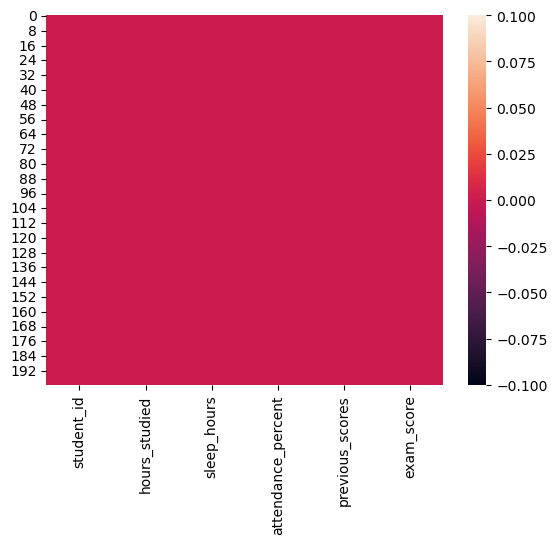

In [16]:
#Creamos un mapa de calor para identificar visualmente los atributos que tienen registros vacíos
sns.heatmap(df.isnull())

In [9]:
df.isnull().sum(axis=0)

student_id            0
hours_studied         0
sleep_hours           0
attendance_percent    0
previous_scores       0
exam_score            0
dtype: int64

In [ ]:
# Revisar si existen duplicados


## Exportar csv

## Análisis de correlación

In [18]:
df.corr(numeric_only=True)

corr_target = df.corr(numeric_only=True)['exam_score'].sort_values(ascending=False)
corr_target

exam_score            1.000000
hours_studied         0.776751
previous_scores       0.431105
attendance_percent    0.225713
sleep_hours           0.188222
Name: exam_score, dtype: float64

Mapa de calor para la correlación

In [20]:
#Correlación con la variable objetivo
corr_target = df.corr(numeric_only=True)['exam_score']
corr_target = corr_target.sort_values(ascending=False)
corr_target

exam_score            1.000000
hours_studied         0.776751
previous_scores       0.431105
attendance_percent    0.225713
sleep_hours           0.188222
Name: exam_score, dtype: float64

In [24]:
weight_corr = pd.DataFrame(df.corr(numeric_only=True)['exam_score'])
weight_corr.columns = ['Correlación']
weight_corr

,Correlación
hours_studied,0.776751
sleep_hours,0.188222
attendance_percent,0.225713
previous_scores,0.431105
exam_score,1.000000


<Axes: >

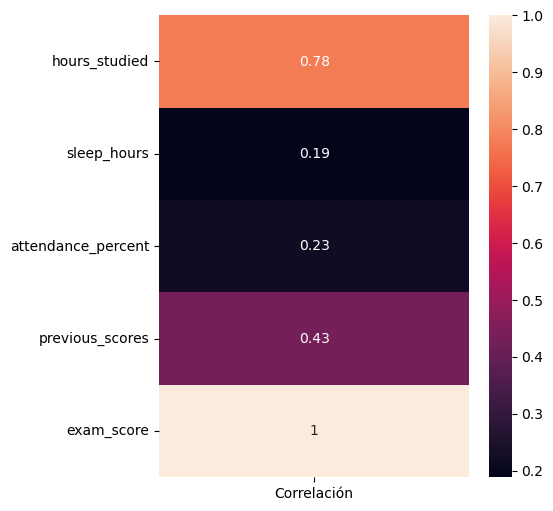

In [25]:
plt.figure(figsize=(5, 6))
sns.heatmap(weight_corr, annot=True)

<Axes: >

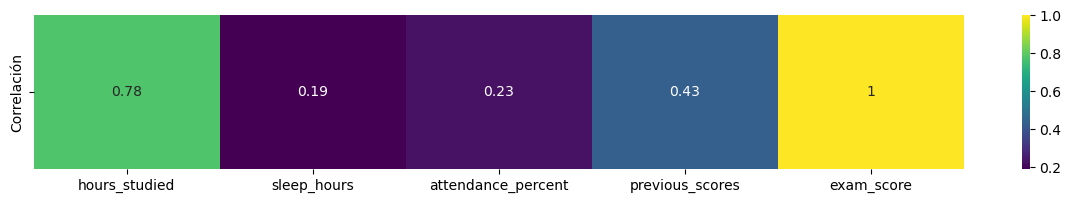

In [26]:
plt.figure(figsize=(15, 2))
sns.heatmap(weight_corr.T, annot=True, cmap='viridis')

# **Regresión lineal**

##Separación de conjunto en atributos y objetivo

Debemos identificar a nuestra variable independiente y a nuestra variable dependiente (variable objetivo).

In [5]:
X = df.drop(columns=['exam_score'])
y = df['exam_score']
X

,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores
0,S001,8.0,8.8,72.1,45
1,S002,1.3,8.6,60.7,55
2,S003,4.0,8.2,73.7,86
3,S004,3.5,4.8,95.1,66
4,S005,9.1,6.4,89.8,71
...,...,...,...,...,...
195,S196,10.5,5.4,94.0,87
196,S197,7.1,6.1,85.1,92
197,S198,1.6,6.9,63.8,76
198,S199,12.0,7.3,50.5,58


In [17]:
y

1       96.9
3       73.1
4       83.1
5       86.5
6       64.1
       ...  
290     71.6
292    110.2
295     56.3
297    102.6
299     56.4
Name: WEIGHT, Length: 153, dtype: float64

Después, separamos nuestro conjunto de datos en el conjunto de prueba y el conjunto de entrenamiento.

Usaremos el 70% de los datos para entrenar a nuestro algoritmo y el 30% para probarlo.

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=0)
y_train

131    28.8
96     36.9
181    36.1
19     17.1
153    33.4
       ... 
67     32.2
192    28.8
117    31.3
47     31.1
172    31.0
Name: exam_score, Length: 140, dtype: float64

## Cálculo de los coeficientes de la ecuación de regresión lineal

Se utiliza el paquete *LinearRegression* para el cálculo de los coeficientes.

In [10]:
from sklearn.linear_model import LinearRegression
LR = LinearRegression()

In [12]:
X = df.drop(columns=['student_id', 'exam_score'])
y = df['exam_score']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=0)

print(X_train.columns)

Index(['hours_studied', 'sleep_hours', 'attendance_percent',
       'previous_scores'],
      dtype='str')


In [13]:
LR.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [14]:
LR.score(X_train, y_train)

0.8230254493618556

In [15]:
pred = LR.predict(X_test)
pred

array([37.62449445, 45.54248008, 37.12851978, 41.09901523, 34.74031328,
       44.4456374 , 35.90977263, 41.20615145, 27.2722992 , 29.04487081,
       35.49159947, 36.97322672, 37.88713881, 26.44299253, 32.35610916,
       23.41338878, 44.14952285, 29.01595642, 35.11896602, 33.39613679,
       22.73882841, 29.46673756, 27.57652231, 28.84862145, 44.06186174,
       39.42403703, 33.37813304, 26.33510643, 44.85798723, 26.36879049,
       24.61395597, 36.93121723, 42.70362644, 32.23116921, 28.72022291,
       27.8582397 , 39.79813519, 40.22021128, 44.88572488, 27.12901644,
       27.94370566, 26.46745165, 28.28834265, 25.19493713, 28.30431769,
       39.56370327, 35.75502602, 28.5960592 , 36.07905509, 39.48402836,
       44.34779644, 22.13824841, 36.15965   , 35.89454055, 26.48878411,
       42.00750379, 36.08996432, 25.74893174, 36.05734627, 31.29201302])

Creamos una tabla para comparar los valores reales y los que el modelo predice.

In [16]:
comparacion = X_test.copy()
comparacion = comparacion.join(y_test)
comparacion['Predicción'] = pred
comparacion

,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score,Predicción
18,9.9,4.8,92.5,54,35.6,37.624494
170,11.3,6.7,85.4,83,45.3,45.542480
107,5.8,8.5,73.1,83,39.2,37.128520
98,11.7,4.4,73.4,70,39.9,41.099015
177,5.7,5.7,74.2,82,31.0,34.740313
182,11.8,5.5,91.5,74,44.1,44.445637
5,8.4,5.1,58.5,75,35.7,35.909773
146,6.9,8.8,97.9,82,45.8,41.206151
12,1.3,6.3,83.6,71,31.2,27.272299
152,5.8,8.7,55.1,44,27.7,29.044871


Imprimimos el valor del coeficiente B1, que representa la pendiente de la recta.

In [17]:
b1 = LR.coef_
print("Coeficiente b1: \n", b1)

Coeficiente b1: 
 [1.57700897 0.77243987 0.09193518 0.16880266]


Imprimimos el valor del coeficiente B0 que representa la intersección con el eje y.

In [18]:
b0 = LR.intercept_
print("Intersección: \n", b0)

Intersección: 
 0.6850464325316707


Graficamos los datos y la recta obtenida.

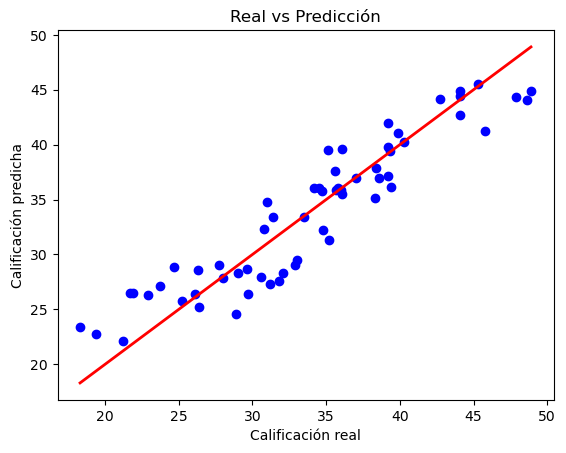

In [21]:
# Plot outputs
pred = LR.predict(X_test)

plt.scatter(y_test, pred, color="blue")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linewidth=2)

plt.xlabel("Calificación real")
plt.ylabel("Calificación predicha")
plt.title("Real vs Predicción")
plt.show()

Predicción del peso para un valor específico de BMI.

##Métricas de evaluación

Aquí hay dos métricas de evaluación comunes para problemas de regresión:

**Error cuadrático medio (varianza):** El MSE es la media de los errores cuadráticos:

$$\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2$$

**R cuadrado:** El valor $$R^2$$ mide la proporción de varianza en la variable objetivo explicada por el modelo. Una puntuación de 1 indica un ajuste perfecto, mientras que una puntuación de 0 indica que el modelo no es mejor que predecir el valor medio de la variable objetivo.

In [22]:
from sklearn import metrics

print('MSE:', metrics.mean_squared_error(y_test, pred))

MSE: 7.368096713003897


In [23]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, pred)
print("R2 score:", r2)

R2 score: 0.8659304575599155


Predicción de BMI para un perfil específico.

In [25]:
X.columns

Index(['hours_studied', 'sleep_hours', 'attendance_percent',
       'previous_scores'],
      dtype='str')

In [27]:
b02 = LR.intercept_
b12 = LR.coef_

# Alumno de ejemplo: 8 h de estudio, 7 h de sueño, 90% de asistencia, 75 en el examen previo
calif = b02 + b12[0]*8 + b12[1]*7 + b12[2]*90 + b12[3]*75
print("La calificación del alumno es de: \n", calif)

La calificación del alumno es de: 
 39.642563003122966
